In [1]:
from pathlib import Path
from collections import Counter
import pandas as pd

# Your exact Kaggle dataset path
dataset = Path(
    "/kaggle/input/datasets/adarshrajbhar1234/full-tool-wear/"
    "Multivariate time series data of milling processes "
    "with varying tool wear and machine tools"
)

# Verify the directory
if not dataset.exists():
    raise FileNotFoundError(f"Dataset not found: {dataset}")

print("Dataset found successfully!")
print("Path:", dataset)

# List all files (without loading their contents)
files = sorted(
    p for p in dataset.rglob("*")
    if p.is_file()
)

print("\nTotal files:", len(files))

# Display first 15 filenames
print("\nFirst 15 files:")
for p in files[:15]:
    print(
        p.relative_to(dataset),
        "|",
        round(p.stat().st_size / (1024**2), 2),
        "MB"
    )

# Count file extensions
print("\nFile types:")
print(Counter(p.suffix.lower() for p in files))

# Find possible metadata files
metadata_files = [
    p for p in files
    if p.name.lower() in (
        "filelist.csv",
        "metadata.csv",
        "labels.csv"
    )
]

if metadata_files:
    for p in metadata_files[:1]:
        print("\nMetadata file:", p.name)

        df = pd.read_csv(p)

        print("\nMetadata columns:")
        print(df.columns.tolist())

        print("\nFirst five rows:")
        print(df.head().to_string(index=False))
else:
    print("\nNo standard metadata CSV found.")

# Inspect one small CSV recording if available
recording_files = [
    p for p in files
    if p.suffix.lower() == ".csv"
    and p not in metadata_files
]

if recording_files:
    sample_file = recording_files[0]

    print("\nSample recording:", sample_file.name)

    try:
        sample = pd.read_csv(sample_file, nrows=5)
        print("\nRecording columns:")
        print(sample.columns.tolist())

        print("\nFirst five rows:")
        print(sample.to_string(index=False))
    except Exception as exc:
        print("Could not inspect recording:", exc)

print("\nInspection complete.")

Dataset found successfully!
Path: /kaggle/input/datasets/adarshrajbhar1234/full-tool-wear/Multivariate time series data of milling processes with varying tool wear and machine tools

Total files: 6419

First 15 files:
M1T1R100C570VB55.h5 | 1.5 MB
M1T1R101C574VB55.h5 | 1.51 MB
M1T1R102C578VB55.h5 | 1.51 MB
M1T1R103C582VB55.h5 | 1.51 MB
M1T1R104C585VB55.h5 | 1.51 MB
M1T1R105C589VB55.h5 | 1.51 MB
M1T1R106C593VB55.h5 | 1.51 MB
M1T1R107C597VB55.h5 | 1.51 MB
M1T1R108C601VB55.h5 | 1.51 MB
M1T1R109C621VB55.h5 | 1.51 MB
M1T1R10C63VB14.h5 | 1.5 MB
M1T1R110C625VB56.h5 | 1.49 MB
M1T1R111C629VB56.h5 | 1.45 MB
M1T1R112C633VB56.h5 | 1.5 MB
M1T1R113C637VB56.h5 | 1.51 MB

File types:
Counter({'.h5': 6418, '.csv': 1})

Metadata file: filelist.csv

Metadata columns:
['filename', 'machine', 'tool', 'run', 'cumulated_tool_contact_time', 'wear']

First five rows:
       filename  machine  tool  run  cumulated_tool_contact_time  wear
M1T1R1C11VB3.h5        1     1    1                           11     3
M1T1

In [2]:
from pathlib import Path
import pandas as pd
import h5py

dataset = Path(
    "/kaggle/input/datasets/adarshrajbhar1234/full-tool-wear/"
    "Multivariate time series data of milling processes "
    "with varying tool wear and machine tools"
)

# Read metadata
meta = pd.read_csv(dataset / "filelist.csv")

print("Total metadata records:", len(meta))
print("Unique machines:", sorted(meta["machine"].unique()))
print("Tool IDs:", sorted(meta["tool"].unique()))

# Treat machine + tool together as physical cutter identity
meta["physical_tool"] = (
    "M" + meta["machine"].astype(str)
    + "T" + meta["tool"].astype(str)
)

print("\nNumber of physical tools:", meta["physical_tool"].nunique())

# Inventory the tools
summary = (
    meta.groupby(["machine", "tool", "physical_tool"])
    .agg(
        recordings=("filename", "count"),
        min_wear=("wear", "min"),
        max_wear=("wear", "max"),
        max_contact_time=("cumulated_tool_contact_time", "max")
    )
    .reset_index()
)

print("\nTool inventory:")
print(summary.to_string(index=False))

# Check whether every metadata entry has an HDF5 file
missing = [
    filename
    for filename in meta["filename"]
    if not (dataset / filename).exists()
]

print("\nMissing HDF5 files:", len(missing))
print("Duplicated filenames:", meta["filename"].duplicated().sum())

# Inspect the first HDF5 file
sample_path = dataset / meta.iloc[0]["filename"]

print("\nInspecting:", sample_path.name)

with h5py.File(sample_path, "r") as h5:
    def inspect(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(
                "Dataset:", name,
                "| Shape:", obj.shape,
                "| Dtype:", obj.dtype
            )

    h5.visititems(inspect)

    print("\nRoot attributes:")
    for key, value in h5.attrs.items():
        print(key, ":", value)

Total metadata records: 6418
Unique machines: [np.int64(1), np.int64(2), np.int64(3)]
Tool IDs: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

Number of physical tools: 9

Tool inventory:
 machine  tool physical_tool  recordings  min_wear  max_wear  max_contact_time
       1     1          M1T1         609         3       158              3458
       1     2          M1T2         609         3       145              3418
       1     3          M1T3         638         3       152              3646
       2     4          M2T4         928         3       149              5171
       2     5          M2T5         928         3       148              5172
       2     6          M2T6         928         3       147              5181
       3     7          M3T7         609         3       153              3439
       3     8          M3T8         560        34       150              3473
       3     9          M3T9 

In [3]:
from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone

dataset = Path(
    "/kaggle/input/datasets/adarshrajbhar1234/full-tool-wear/"
    "Multivariate time series data of milling processes "
    "with varying tool wear and machine tools"
)

output_dir = Path("/kaggle/working/nine_tool_validation")
output_dir.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(dataset / "filelist.csv")

meta["physical_tool"] = (
    "M" + meta["machine"].astype(str)
    + "T" + meta["tool"].astype(str)
)

# Previously specified protocol:
# Highest numbered tool from each machine is held out.
test_tools = ["M1T3", "M2T6", "M3T9"]

source_tools = [
    "M1T1", "M1T2",
    "M2T4", "M2T5",
    "M3T7", "M3T8"
]

assert len(meta) == 6418
assert meta["filename"].is_unique

assert set(meta["physical_tool"].unique()) == (
    set(source_tools) | set(test_tools)
)

assert not (set(source_tools) & set(test_tools))

meta["split"] = meta["physical_tool"].apply(
    lambda t: "test" if t in test_tools else "source"
)

print("=== FROZEN DATASET SPLIT ===")
print(meta.groupby(["split", "physical_tool"]).size())

print("\n=== TOTALS ===")
print(meta["split"].value_counts())

assert (meta["split"] == "source").sum() == 4243
assert (meta["split"] == "test").sum() == 2175

# Record provenance
metadata_hash = hashlib.sha256(
    (dataset / "filelist.csv").read_bytes()
).hexdigest()

protocol = {
    "protocol_id": "stiehl9tool_predeclared_v1",
    "dataset_version": 3,
    "metadata_sha256": metadata_hash,
    "source_tools": source_tools,
    "test_tools": test_tools,
    "source_recordings": 4243,
    "test_recordings": 2175,
    "force_channels": [
        "signals_sensor/force_sensor_x",
        "signals_sensor/force_sensor_y",
        "signals_sensor/force_sensor_z"
    ],
    "feature_region": "central_80_percent",
    "nominal_sampling_hz": 25000,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "note": (
        "This freezes the previously documented split. "
        "Final test outcomes must not guide model selection."
    )
}

meta.to_csv(output_dir / "dataset_split.csv", index=False)

with open(output_dir / "frozen_protocol.json", "w") as f:
    json.dump(protocol, f, indent=2)

print("\nProtocol saved:")
print(output_dir / "frozen_protocol.json")

print("Split CSV saved:")
print(output_dir / "dataset_split.csv")

print("\nSUCCESS: Tool-level separation verified.")

=== FROZEN DATASET SPLIT ===
split   physical_tool
source  M1T1             609
        M1T2             609
        M2T4             928
        M2T5             928
        M3T7             609
        M3T8             560
test    M1T3             638
        M2T6             928
        M3T9             609
dtype: int64

=== TOTALS ===
split
source    4243
test      2175
Name: count, dtype: int64

Protocol saved:
/kaggle/working/nine_tool_validation/frozen_protocol.json
Split CSV saved:
/kaggle/working/nine_tool_validation/dataset_split.csv

SUCCESS: Tool-level separation verified.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
from scipy.signal import welch
from scipy.stats import skew, kurtosis
from tqdm.auto import tqdm
import json

dataset = Path(
    "/kaggle/input/datasets/adarshrajbhar1234/full-tool-wear/"
    "Multivariate time series data of milling processes "
    "with varying tool wear and machine tools"
)

out = Path("/kaggle/working/nine_tool_validation")
out.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(out / "dataset_split.csv")

CHANNELS = {
    "Fx": "signals_sensor/force_sensor_x",
    "Fy": "signals_sensor/force_sensor_y",
    "Fz": "signals_sensor/force_sensor_z",
}

FS = 25000

# Fixed frequency bands in Hz.
# Record these choices before assessing held-out performance.
BANDS = [
    (0, 500),
    (500, 1500),
    (1500, 5000),
    (5000, 12500),
]

FEATURE_NAMES = [
    "mean", "std", "rms", "min", "max",
    "ptp", "skew", "kurtosis",
    "energy_0", "energy_1",
    "energy_2", "energy_3",
]

def extract_channel_features(signal):
    x = np.asarray(signal, dtype=np.float64).ravel()

    # Central 80% of the signal
    start = int(len(x) * 0.10)
    end = int(len(x) * 0.90)
    x = x[start:end]

    if len(x) < 2048 or not np.isfinite(x).all():
        raise ValueError("Signal too short or contains nonfinite data")

    features = [
        np.mean(x),
        np.std(x),
        np.sqrt(np.mean(x**2)),
        np.min(x),
        np.max(x),
        np.ptp(x),
        skew(x, bias=False),
        kurtosis(x, fisher=True, bias=False),
    ]

    # Welch power spectral density
    frequencies, psd = welch(
        x,
        fs=FS,
        nperseg=2048,
        noverlap=1024,
        detrend="constant",
        scaling="density",
    )

    df = frequencies[1] - frequencies[0]

    for i, (low, high) in enumerate(BANDS):
        if i == len(BANDS) - 1:
            mask = (frequencies >= low) & (frequencies <= high)
        else:
            mask = (frequencies >= low) & (frequencies < high)

        energy = np.sum(psd[mask]) * df
        features.append(energy)

    return features


def extract_recording(record):
    path = dataset / record["filename"]

    result = {
        "filename": record["filename"],
        "machine": int(record["machine"]),
        "tool": int(record["tool"]),
        "physical_tool": record["physical_tool"],
        "run": int(record["run"]),
        "cumulated_tool_contact_time":
            float(record["cumulated_tool_contact_time"]),
        "wear": float(record["wear"]),
        "split": record["split"],
    }

    with h5py.File(path, "r") as h5:
        for prefix, key in CHANNELS.items():
            signal = h5[key][()]

            values = extract_channel_features(signal)

            for name, value in zip(FEATURE_NAMES, values):
                result[f"{prefix}_{name}"] = float(value)

    return result


# Save in separate batches for safe restarts
batch_dir = out / "feature_batches"
batch_dir.mkdir(exist_ok=True)

BATCH_SIZE = 100

records = meta.to_dict("records")
errors = []

for start in tqdm(
    range(0, len(records), BATCH_SIZE),
    desc="Extracting batches"
):
    batch_number = start // BATCH_SIZE
    batch_file = batch_dir / f"batch_{batch_number:04d}.csv"

    # Skip batches already completed
    if batch_file.exists():
        continue

    batch = records[start:start + BATCH_SIZE]
    rows = []

    for record in batch:
        try:
            rows.append(extract_recording(record))
        except Exception as exc:
            errors.append({
                "filename": record["filename"],
                "error": str(exc),
            })

    pd.DataFrame(rows).to_csv(batch_file, index=False)


# Combine all completed batches
batch_files = sorted(batch_dir.glob("batch_*.csv"))

features = pd.concat(
    [pd.read_csv(f) for f in batch_files],
    ignore_index=True
)

features = features.sort_values(
    ["machine", "tool", "run"]
).reset_index(drop=True)

feature_cols = [
    f"{channel}_{feature}"
    for channel in CHANNELS
    for feature in FEATURE_NAMES
]

# Save the complete feature table
output_file = out / "nine_tool_features.csv"
features.to_csv(output_file, index=False)

# Record feature-extraction settings
settings = {
    "channels": CHANNELS,
    "sampling_frequency_hz": FS,
    "central_signal_fraction": 0.8,
    "time_domain_statistics": FEATURE_NAMES[:8],
    "frequency_bands_hz": BANDS,
    "psd_method": "scipy.signal.welch",
    "features_per_channel": 12,
    "total_features": len(feature_cols),
}

with open(out / "feature_extraction_config.json", "w") as f:
    json.dump(settings, f, indent=2)

# Quality checks
print("\n=== FEATURE EXTRACTION RESULTS ===")
print("Extracted recordings:", len(features))
print("Expected recordings:", len(meta))
print("Feature columns:", len(feature_cols))
print("Failed files:", len(errors))
print("Duplicate filenames:", features["filename"].duplicated().sum())

if errors:
    pd.DataFrame(errors).to_csv(
        out / "feature_extraction_errors.csv",
        index=False
    )
    print("First errors:", errors[:5])

if len(features) == len(meta):
    assert set(features["filename"]) == set(meta["filename"])
    assert features[feature_cols].notna().all().all()
    assert np.isfinite(features[feature_cols].to_numpy()).all()

    print("\nSUCCESS: All 6,418 recordings processed.")
else:
    print("\nINCOMPLETE: Check missing recordings and errors.")

print("\nSaved:", output_file)

print("\nFeature preview:")
print(
    features[
        ["physical_tool", "run", "split"] + feature_cols[:5]
    ].head().to_string(index=False)
)

Extracting batches:   0%|          | 0/65 [00:00<?, ?it/s]


=== FEATURE EXTRACTION RESULTS ===
Extracted recordings: 6418
Expected recordings: 6418
Feature columns: 36
Failed files: 0
Duplicate filenames: 0

SUCCESS: All 6,418 recordings processed.

Saved: /kaggle/working/nine_tool_validation/nine_tool_features.csv

Feature preview:
physical_tool  run  split    Fx_mean    Fx_std     Fx_rms    Fx_min     Fx_max
         M1T1    1 source 162.083882 82.064087 181.674707 -6.323035 376.743103
         M1T1    2 source 164.130440 81.624985 183.306954 -3.038304 382.577637
         M1T1    3 source 166.180570 81.124176 184.924616  0.248336 388.089508
         M1T1    4 source 167.493351 80.786303 185.958193  1.788779 382.305786
         M1T1    5 source 168.458147 80.882555 186.869300  1.894554 383.686157


In [5]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import json
import hashlib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone
import sklearn

# =====================================================
# 1. Load the extracted features
# =====================================================

out = Path("/kaggle/working/nine_tool_validation")

features_path = out / "nine_tool_features.csv"
split_path = out / "dataset_split.csv"

df = pd.read_csv(features_path)
split_manifest = pd.read_csv(split_path)

assert len(df) == 6418
assert df["filename"].is_unique
assert set(df["filename"]) == set(split_manifest["filename"])

# Confirm the saved split has not changed
original_split = split_manifest.set_index("filename")["split"]
assert all(
    df.set_index("filename").loc[original_split.index, "split"]
    == original_split
)

SOURCE_TOOLS = [
    "M1T1", "M1T2",
    "M2T4", "M2T5",
    "M3T7", "M3T8"
]

TEST_TOOLS = ["M1T3", "M2T6", "M3T9"]

# Load only source recordings for model development
source = df.loc[df["split"] == "source"].copy()

assert len(source) == 4243
assert set(source["physical_tool"]) == set(SOURCE_TOOLS)
assert not set(source["physical_tool"]) & set(TEST_TOOLS)

# Only sensor-derived features.
# No run, wear, machine, tool ID, or contact time as inputs.
feature_cols = [
    f"{channel}_{feature}"
    for channel in ["Fx", "Fy", "Fz"]
    for feature in [
        "mean", "std", "rms", "min", "max",
        "ptp", "skew", "kurtosis",
        "energy_0", "energy_1",
        "energy_2", "energy_3"
    ]
]

assert len(feature_cols) == 36
assert all(c in source.columns for c in feature_cols)

X = source[feature_cols].to_numpy(dtype=np.float64)
y = source["wear"].to_numpy(dtype=np.float64)
groups = source["physical_tool"].to_numpy()

assert np.isfinite(X).all()
assert np.isfinite(y).all()

print("Source recordings:", len(source))
print("Input features:", X.shape[1])
print("Source cutters:", SOURCE_TOOLS)


# =====================================================
# 2. Freeze the Random Forest configuration
# =====================================================

rf_config = {
    "n_estimators": 300,
    "max_features": "sqrt",
    "min_samples_leaf": 3,
    "random_state": 42,
    "n_jobs": -1,
}

base_model = RandomForestRegressor(**rf_config)


# =====================================================
# 3. Leave-one-source-tool-out validation
# =====================================================

oof_predictions = np.full(len(source), np.nan)
fold_results = []

for held_out_tool in SOURCE_TOOLS:

    train_mask = groups != held_out_tool
    val_mask = groups == held_out_tool

    assert set(groups[train_mask]).isdisjoint(
        set(groups[val_mask])
    )

    model = clone(base_model)

    model.fit(
        X[train_mask],
        y[train_mask]
    )

    predictions = model.predict(X[val_mask])

    oof_predictions[val_mask] = predictions

    actual = y[val_mask]

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    r2 = r2_score(actual, predictions)

    fold_results.append({
        "held_out_tool": held_out_tool,
        "training_tools": int(len(set(groups[train_mask]))),
        "validation_recordings": int(val_mask.sum()),
        "mae_um": float(mae),
        "rmse_um": float(rmse),
        "r2": float(r2),
        "mean_signed_error_um":
            float(np.mean(predictions - actual))
    })

    print(
        f"{held_out_tool}: "
        f"MAE={mae:.3f} µm | "
        f"RMSE={rmse:.3f} µm | "
        f"R²={r2:.3f}"
    )

assert np.isfinite(oof_predictions).all()

results = pd.DataFrame(fold_results)

print("\n=== SOURCE-TOOL VALIDATION ===")
print(results.to_string(index=False))

print("\nMacro MAE:", round(results["mae_um"].mean(), 3))
print("Macro RMSE:", round(results["rmse_um"].mean(), 3))
print("Macro R²:", round(results["r2"].mean(), 3))


# =====================================================
# 4. Save source-only prediction residuals
# =====================================================

oof = source[
    ["filename", "physical_tool", "run", "wear"]
].copy()

oof["prediction_um"] = oof_predictions
oof["absolute_error_um"] = np.abs(
    oof["prediction_um"] - oof["wear"]
)
oof["signed_error_um"] = (
    oof["prediction_um"] - oof["wear"]
)

oof.to_csv(
    out / "rf_source_tool_oof_predictions.csv",
    index=False
)

results.to_csv(
    out / "rf_source_tool_validation.csv",
    index=False
)

# Exploratory cross-tool residual threshold.
# NOT a distribution-free conformal guarantee.
q90 = float(
    np.quantile(
        oof["absolute_error_um"].to_numpy(),
        0.90,
        method="higher"
    )
)

print("\nSource OOF 90th-percentile absolute error:",
      round(q90, 3), "µm")


# =====================================================
# 5. Fit final RF using all six source cutters
# =====================================================

final_rf = clone(base_model)
final_rf.fit(X, y)

joblib.dump(
    final_rf,
    out / "rf_six_source_tools.joblib"
)

# Verify model serialization
loaded_rf = joblib.load(out / "rf_six_source_tools.joblib")

assert np.allclose(
    final_rf.predict(X[:10]),
    loaded_rf.predict(X[:10]),
    rtol=0,
    atol=1e-10
)

# =====================================================
# 6. Save reproducibility manifest
# =====================================================

manifest = {
    "experiment": "nine_tool_rf_source_only_v1",
    "source_tools": SOURCE_TOOLS,
    "reserved_test_tools": TEST_TOOLS,
    "source_recordings": len(source),
    "feature_columns": feature_cols,
    "random_forest": rf_config,
    "scikit_learn_version": sklearn.__version__,
    "feature_csv_sha256": hashlib.sha256(
        features_path.read_bytes()
    ).hexdigest(),
    "validation": "leave_one_source_tool_out",
    "macro_source_mae_um":
        float(results["mae_um"].mean()),
    "source_oof_abs_error_q90_um": q90,
    "calibration_warning": (
        "OOF residual quantile is exploratory. "
        "Not a guaranteed conformal threshold "
        "under unseen physical-tool shift."
    ),
    "final_test_evaluated": False
}

with open(out / "rf_experiment_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print("\nSUCCESS: Source-only RF experiment completed.")
print("Final-test tools were not evaluated.")

print("\nSaved files:")
for name in [
    "rf_source_tool_oof_predictions.csv",
    "rf_source_tool_validation.csv",
    "rf_six_source_tools.joblib",
    "rf_experiment_manifest.json"
]:
    print(" -", out / name)

Source recordings: 4243
Input features: 36
Source cutters: ['M1T1', 'M1T2', 'M2T4', 'M2T5', 'M3T7', 'M3T8']
M1T1: MAE=10.638 µm | RMSE=13.077 µm | R²=0.835
M1T2: MAE=7.868 µm | RMSE=10.510 µm | R²=0.844
M2T4: MAE=3.839 µm | RMSE=5.439 µm | R²=0.967
M2T5: MAE=4.235 µm | RMSE=6.564 µm | R²=0.947
M3T7: MAE=12.729 µm | RMSE=14.068 µm | R²=0.813
M3T8: MAE=9.106 µm | RMSE=10.283 µm | R²=0.876

=== SOURCE-TOOL VALIDATION ===
held_out_tool  training_tools  validation_recordings    mae_um   rmse_um       r2  mean_signed_error_um
         M1T1               5                    609 10.637889 13.076735 0.834906             -8.845512
         M1T2               5                    609  7.868010 10.510348 0.844405              7.368767
         M2T4               5                    928  3.839486  5.438703 0.966578             -1.236282
         M2T5               5                    928  4.234908  6.564337 0.947001              0.376106
         M3T7               5                    609 12.72

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

from sklearn.ensemble import RandomForestRegressor
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error

out = Path("/kaggle/working/nine_tool_validation")
df = pd.read_csv(out / "nine_tool_features.csv")

SOURCE_TOOLS = [
    "M1T1", "M1T2", "M2T4",
    "M2T5", "M3T7", "M3T8"
]

feature_cols = [
    f"{ch}_{name}"
    for ch in ["Fx", "Fy", "Fz"]
    for name in [
        "mean", "std", "rms", "min", "max",
        "ptp", "skew", "kurtosis",
        "energy_0", "energy_1",
        "energy_2", "energy_3"
    ]
]

source = df[df["split"] == "source"].copy()
assert len(source) == 4243
assert set(source["physical_tool"]) == set(SOURCE_TOOLS)

X = source[feature_cols].to_numpy(dtype=float)
y = source["wear"].to_numpy(dtype=float)
groups = source["physical_tool"].to_numpy()

N_MEMBERS = 5
SEEDS = [42, 43, 44, 45, 46]

ensemble_mean = np.full(len(source), np.nan)
ensemble_sd = np.full(len(source), np.nan)

# Each member uses a seeded stratified bootstrap
# of recordings from the training tools.
def bootstrap_indices(training_indices, seed):
    rng = np.random.default_rng(seed)
    chosen = []

    for tool in sorted(set(groups[training_indices])):
        idx = training_indices[
            groups[training_indices] == tool
        ]
        chosen.append(
            rng.choice(idx, size=len(idx), replace=True)
        )

    return np.concatenate(chosen)

print("Training source-only RF ensembles...")

for held_out in SOURCE_TOOLS:
    train_idx = np.where(groups != held_out)[0]
    val_idx = np.where(groups == held_out)[0]

    member_predictions = []

    for seed in SEEDS:
        boot_idx = bootstrap_indices(train_idx, seed)

        model = RandomForestRegressor(
            n_estimators=300,
            max_features="sqrt",
            min_samples_leaf=3,
            random_state=seed,
            n_jobs=-1
        )

        model.fit(X[boot_idx], y[boot_idx])

        member_predictions.append(
            model.predict(X[val_idx])
        )

    preds = np.column_stack(member_predictions)

    ensemble_mean[val_idx] = preds.mean(axis=1)
    ensemble_sd[val_idx] = preds.std(axis=1, ddof=1)

    print(f"Completed {held_out}")

assert np.isfinite(ensemble_mean).all()
assert np.isfinite(ensemble_sd).all()

source["ensemble_prediction_um"] = ensemble_mean
source["ensemble_sd_um"] = ensemble_sd
source["absolute_error_um"] = np.abs(
    ensemble_mean - y
)

results = []

for tool in SOURCE_TOOLS:
    part = source[source["physical_tool"] == tool].copy()

    full_mae = mean_absolute_error(
        part["wear"],
        part["ensemble_prediction_um"]
    )

    # Reject the highest-disagreement 20% of this
    # source validation cutter for diagnostic analysis.
    # These per-tool cutoffs are NOT deployment thresholds.
    threshold = part["ensemble_sd_um"].quantile(0.8)

    kept = part[part["ensemble_sd_um"] <= threshold]

    retained_mae = mean_absolute_error(
        kept["wear"],
        kept["ensemble_prediction_um"]
    )

    rho, pvalue = spearmanr(
        part["ensemble_sd_um"],
        part["absolute_error_um"]
    )

    results.append({
        "tool": tool,
        "n": len(part),
        "full_mae_um": full_mae,
        "retained_mae_um": retained_mae,
        "mae_change_um": retained_mae - full_mae,
        "spearman_rho": rho,
        "spearman_pvalue_descriptive": pvalue,
        "mean_ensemble_sd_um":
            part["ensemble_sd_um"].mean()
    })

result_df = pd.DataFrame(results)

print("\n=== SOURCE ENSEMBLE DIAGNOSTICS ===")
print(result_df.round(4).to_string(index=False))

print("\nMacro ensemble MAE:",
      round(result_df["full_mae_um"].mean(), 3))

print("Macro retained MAE:",
      round(result_df["retained_mae_um"].mean(), 3))

source.to_csv(
    out / "rf_ensemble_source_predictions.csv",
    index=False
)

result_df.to_csv(
    out / "rf_ensemble_source_diagnostics.csv",
    index=False
)

config = {
    "experiment": "source_tool_rf_bootstrap_ensemble_v1",
    "members": N_MEMBERS,
    "seeds": SEEDS,
    "bootstrap": "within_training_tool_recordings",
    "trees_per_member": 300,
    "held_out_tools": SOURCE_TOOLS,
    "final_test_evaluated": False,
    "notes": [
        "Only source tools used",
        "Per-tool rejection threshold is diagnostic",
        "Temporal dependence makes nominal p-values unreliable",
        "Ensemble spread is not calibrated uncertainty"
    ]
}

with open(out / "rf_ensemble_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nSUCCESS: Source ensemble diagnostics saved.")
print("Final-test cutters remain untouched.")

Training source-only RF ensembles...
Completed M1T1
Completed M1T2
Completed M2T4
Completed M2T5
Completed M3T7
Completed M3T8

=== SOURCE ENSEMBLE DIAGNOSTICS ===
tool   n  full_mae_um  retained_mae_um  mae_change_um  spearman_rho  spearman_pvalue_descriptive  mean_ensemble_sd_um
M1T1 609      10.5969           9.8773        -0.7196        0.2458                       0.0000               0.5968
M1T2 609       7.7261           8.1586         0.4325       -0.0888                       0.0285               0.8951
M2T4 928       3.5412           2.8154        -0.7258        0.4696                       0.0000               0.5254
M2T5 928       4.2372           3.3973        -0.8398        0.4652                       0.0000               0.7584
M3T7 609      12.7752          12.5191        -0.2561        0.0572                       0.1584               0.6602
M3T8 560       8.9592           8.7982        -0.1610        0.1792                       0.0000               0.8051

Macro ens

In [7]:
from pathlib import Path
import numpy as np
import pandas as pd
import json

out = Path("/kaggle/working/nine_tool_validation")

df = pd.read_csv(
    out / "rf_ensemble_source_predictions.csv"
)

source_tools = [
    "M1T1", "M1T2", "M2T4",
    "M2T5", "M3T7", "M3T8"
]

assert len(df) == 4243
assert set(df["physical_tool"]) == set(source_tools)
assert set(df["split"]) == {"source"}

# Fixed analysis settings
ALPHA = 0.10
SD_FLOOR = 1.0  # µm

df["residual"] = np.abs(
    df["wear"] - df["ensemble_prediction_um"]
)

df["scale"] = df["ensemble_sd_um"] + SD_FLOOR

df["adaptive_score"] = (
    df["residual"] / df["scale"]
)


def finite_quantile(values, alpha=0.10):
    values = np.sort(np.asarray(values, dtype=float))
    n = len(values)

    # Finite-sample quantile index.
    # This does not by itself provide a coverage
    # guarantee under physical-tool shift.
    k = int(np.ceil((n + 1) * (1 - alpha)))

    if k > n:
        return np.inf

    return float(values[k - 1])


results = []

# Diagnostic: calibrate using residuals from
# five source tools, assess the sixth.
for tool in source_tools:

    calibration = df[df["physical_tool"] != tool]
    evaluation = df[df["physical_tool"] == tool]

    q_standard = finite_quantile(
        calibration["residual"],
        ALPHA
    )

    q_adaptive = finite_quantile(
        calibration["adaptive_score"],
        ALPHA
    )

    y = evaluation["wear"].to_numpy()
    pred = evaluation["ensemble_prediction_um"].to_numpy()
    scale = evaluation["scale"].to_numpy()

    # Standard interval
    lower_std = pred - q_standard
    upper_std = pred + q_standard

    # Adaptive interval
    half_width_adaptive = q_adaptive * scale

    lower_ad = pred - half_width_adaptive
    upper_ad = pred + half_width_adaptive

    coverage_std = np.mean(
        (y >= lower_std) & (y <= upper_std)
    )

    coverage_ad = np.mean(
        (y >= lower_ad) & (y <= upper_ad)
    )

    results.append({
        "tool": tool,
        "n": len(evaluation),
        "standard_coverage": coverage_std,
        "standard_width_um": 2 * q_standard,
        "adaptive_coverage": coverage_ad,
        "adaptive_width_um": np.mean(
            2 * half_width_adaptive
        ),
        "q_standard_um": q_standard,
        "q_adaptive": q_adaptive
    })


results_df = pd.DataFrame(results)

print("=== SOURCE-ONLY INTERVAL DIAGNOSTICS ===")
print(results_df.round(4).to_string(index=False))

print("\nMacro standard coverage:",
      round(results_df["standard_coverage"].mean() * 100, 2),
      "%")

print("Macro adaptive coverage:",
      round(results_df["adaptive_coverage"].mean() * 100, 2),
      "%")

print("\nMacro standard width:",
      round(results_df["standard_width_um"].mean(), 3),
      "µm")

print("Macro adaptive width:",
      round(results_df["adaptive_width_um"].mean(), 3),
      "µm")


# Source-derived thresholds for the eventual
# final evaluation, not tuned on final-test results.
final_q_standard = finite_quantile(
    df["residual"],
    ALPHA
)

final_q_adaptive = finite_quantile(
    df["adaptive_score"],
    ALPHA
)

print("\n=== FROZEN SOURCE-DERIVED THRESHOLDS ===")
print("Standard half-width:",
      round(final_q_standard, 4), "µm")
print("Adaptive multiplier:",
      round(final_q_adaptive, 4))

results_df.to_csv(
    out / "source_interval_diagnostics.csv",
    index=False
)

config = {
    "experiment": "nine_tool_source_intervals_v1",
    "nominal_coverage": 0.90,
    "alpha": ALPHA,
    "adaptive_sd_floor_um": SD_FLOOR,
    "standard_quantile_um": final_q_standard,
    "adaptive_quantile": final_q_adaptive,
    "calibration_data": "source-tool OOF predictions",
    "final_test_evaluated": False,
    "limitations": [
        "No exchangeability guarantee across cutters",
        "Source OOF models have overlapping training sets",
        "Calibration and evaluation folds are not independent",
        "Sequential observations are dependent",
        "This is a source-only diagnostic"
    ]
}

with open(out / "source_interval_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("\nSUCCESS: Source interval diagnostics saved.")
print("Final-test cutters remain untouched.")

=== SOURCE-ONLY INTERVAL DIAGNOSTICS ===
tool   n  standard_coverage  standard_width_um  adaptive_coverage  adaptive_width_um  q_standard_um  q_adaptive
M1T1 609             0.7603            32.1046             0.7126            29.5109        16.0523      9.2404
M1T2 609             0.8621            33.4807             0.8966            38.2532        16.7403     10.0927
M2T4 928             0.9946            35.6164             0.9989            32.9262        17.8082     10.7926
M2T5 928             0.9709            35.2943             0.9989            37.9545        17.6471     10.7926
M3T7 609             0.7323            31.8813             0.6141            29.2593        15.9406      8.8117
M3T8 560             0.9089            34.0218             0.9518            37.1673        17.0109     10.2951

Macro standard coverage: 87.15 %
Macro adaptive coverage: 86.22 %

Macro standard width: 33.733 µm
Macro adaptive width: 34.179 µm

=== FROZEN SOURCE-DERIVED THRESHOLDS ===
S

In [8]:
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import json
import hashlib
import sklearn
from sklearn.ensemble import RandomForestRegressor

# ==================================================
# STEP 7: FINAL SOURCE-ONLY ENSEMBLE
# ==================================================

out = Path("/kaggle/working/nine_tool_validation")
model_dir = out / "final_ensemble_models"
model_dir.mkdir(parents=True, exist_ok=True)

features_path = out / "nine_tool_features.csv"
df = pd.read_csv(features_path)

with open(out / "frozen_protocol.json") as f:
    protocol = json.load(f)

with open(out / "source_interval_config.json") as f:
    interval_config = json.load(f)

SOURCE_TOOLS = protocol["source_tools"]
TEST_TOOLS = protocol["test_tools"]

# Validate the frozen split
assert len(df) == 6418
assert df["filename"].is_unique
assert set(SOURCE_TOOLS).isdisjoint(TEST_TOOLS)

source = df[df["split"] == "source"].copy()

assert len(source) == 4243
assert set(source["physical_tool"]) == set(SOURCE_TOOLS)
assert not source["physical_tool"].isin(TEST_TOOLS).any()

FEATURE_NAMES = [
    "mean", "std", "rms", "min", "max",
    "ptp", "skew", "kurtosis",
    "energy_0", "energy_1",
    "energy_2", "energy_3"
]

feature_cols = [
    f"{ch}_{name}"
    for ch in ["Fx", "Fy", "Fz"]
    for name in FEATURE_NAMES
]

X = source[feature_cols].to_numpy(dtype=np.float64)
y = source["wear"].to_numpy(dtype=np.float64)
groups = source["physical_tool"].to_numpy()

assert X.shape == (4243, 36)
assert np.isfinite(X).all()
assert np.isfinite(y).all()

SEEDS = [42, 43, 44, 45, 46]
N_MEMBERS = len(SEEDS)

def stratified_bootstrap(seed):
    rng = np.random.default_rng(seed)

    sampled_indices = []

    for tool in SOURCE_TOOLS:
        indices = np.where(groups == tool)[0]

        sampled = rng.choice(
            indices,
            size=len(indices),
            replace=True
        )

        sampled_indices.append(sampled)

    return np.concatenate(sampled_indices)


print("Training final five-member ensemble...")

model_files = []

for i, seed in enumerate(SEEDS, start=1):

    bootstrap_idx = stratified_bootstrap(seed)

    model = RandomForestRegressor(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=3,
        random_state=seed,
        n_jobs=-1
    )

    model.fit(
        X[bootstrap_idx],
        y[bootstrap_idx]
    )

    filename = f"rf_member_{i:02d}_seed_{seed}.joblib"
    filepath = model_dir / filename

    joblib.dump(model, filepath)

    # Verify saved-model predictions
    restored = joblib.load(filepath)

    assert np.allclose(
        model.predict(X[:10]),
        restored.predict(X[:10]),
        rtol=0,
        atol=1e-10
    )

    model_files.append(str(filepath))

    print(f"Saved member {i}/{N_MEMBERS}: {filename}")


# ==================================================
# FROZEN FINAL-EVALUATION SETTINGS
# ==================================================

q_standard = float(
    interval_config["standard_quantile_um"]
)

q_adaptive = float(
    interval_config["adaptive_quantile"]
)

assert interval_config["alpha"] == 0.10
assert interval_config["adaptive_sd_floor_um"] == 1.0

assert q_standard > 0
assert q_adaptive > 0

evaluation_plan = {
    "experiment": "nine_tool_final_evaluation_v1",
    "status": "models_trained_test_not_evaluated",
    "source_tools": SOURCE_TOOLS,
    "test_tools": TEST_TOOLS,
    "n_source": 4243,
    "n_test_expected": 2175,
    "feature_columns": feature_cols,
    "ensemble_seeds": SEEDS,
    "ensemble_members": N_MEMBERS,
    "model_files": model_files,
    "features_sha256": hashlib.sha256(
        features_path.read_bytes()
    ).hexdigest(),
    "model_sha256": {
        Path(p).name: hashlib.sha256(
            Path(p).read_bytes()
        ).hexdigest()
        for p in model_files
    },
    "standard_half_width_um": q_standard,
    "adaptive_multiplier": q_adaptive,
    "adaptive_sd_floor_um": 1.0,
    "nominal_coverage": 0.90,
    "primary_metrics": [
        "per_tool_mae",
        "macro_mae",
        "per_tool_rmse",
        "macro_rmse",
        "per_tool_signed_error",
        "standard_interval_coverage",
        "adaptive_interval_coverage",
        "standard_interval_width",
        "adaptive_interval_width"
    ],
    "secondary_metrics": [
        "spearman_disagreement_absolute_error",
        "selective_mae_at_80_percent_retention"
    ],
    "limitations": [
        "One held-out cutter per machine",
        "Not an unseen-machine experiment",
        "No exchangeability guarantee for intervals",
        "Source OOF calibration is heuristic",
        "Temporally dependent observations",
        "Test predictions must not guide method changes"
    ],
    "scikit_learn_version": sklearn.__version__
}

manifest_path = out / "final_evaluation_plan.json"

# Avoid silently replacing an already frozen plan.
if manifest_path.exists():
    with open(manifest_path) as f:
        previous = json.load(f)

    assert previous == evaluation_plan, (
        "A different final evaluation plan already exists. "
        "Do not overwrite it without documenting the change."
    )
else:
    with open(manifest_path, "w") as f:
        json.dump(evaluation_plan, f, indent=2)

print("\n=== FINAL ENSEMBLE READY ===")
print("Members:", len(model_files))
print("Training recordings:", len(source))
print("Reserved test recordings:", 2175)

print("\nFrozen standard half-width:",
      round(q_standard, 4), "µm")

print("Frozen adaptive multiplier:",
      round(q_adaptive, 4))

print("\nSaved evaluation plan:", manifest_path)
print("Final-test cutters have NOT been evaluated.")

Training final five-member ensemble...
Saved member 1/5: rf_member_01_seed_42.joblib
Saved member 2/5: rf_member_02_seed_43.joblib
Saved member 3/5: rf_member_03_seed_44.joblib
Saved member 4/5: rf_member_04_seed_45.joblib
Saved member 5/5: rf_member_05_seed_46.joblib

=== FINAL ENSEMBLE READY ===
Members: 5
Training recordings: 4243
Reserved test recordings: 2175

Frozen standard half-width: 16.9765 µm
Frozen adaptive multiplier: 10.1004

Saved evaluation plan: /kaggle/working/nine_tool_validation/final_evaluation_plan.json
Final-test cutters have NOT been evaluated.


In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib

out = Path("/kaggle/working/nine_tool_validation")

with open(out / "final_evaluation_plan.json") as f:
    plan = json.load(f)

source_pred = pd.read_csv(
    out / "rf_ensemble_source_predictions.csv"
)

assert len(source_pred) == 4243
assert set(source_pred["physical_tool"]) == set(plan["source_tools"])
assert set(source_pred["split"]) == {"source"}

# Select the bottom 80% of source disagreement values.
sd_threshold = float(
    np.quantile(
        source_pred["ensemble_sd_um"].to_numpy(),
        0.80,
        method="higher"
    )
)

# Freeze the complete evaluation specification.
spec = {
    "evaluation_id": "nine_tool_final_v1",
    "test_tools": plan["test_tools"],
    "source_tools": plan["source_tools"],
    "feature_columns": plan["feature_columns"],
    "features_sha256": plan["features_sha256"],
    "model_sha256": plan["model_sha256"],
    "single_rf_model": "rf_six_source_tools.joblib",
    "ensemble_model_files": [
        Path(p).name for p in plan["model_files"]
    ],
    "standard_half_width_um":
        plan["standard_half_width_um"],
    "adaptive_multiplier":
        plan["adaptive_multiplier"],
    "adaptive_sd_floor_um":
        plan["adaptive_sd_floor_um"],
    "source_sd_threshold_um": sd_threshold,
    "nominal_coverage": 0.90,
    "uncertainty_rejection_rule":
        "retain predictions with ensemble_sd <= source threshold",
    "interval_rule":
        "symmetric unbounded prediction intervals",
    "primary_metrics": [
        "single_rf_mae",
        "ensemble_mae",
        "ensemble_rmse",
        "ensemble_mean_signed_error",
        "standard_coverage",
        "adaptive_coverage",
        "standard_interval_width",
        "adaptive_interval_width"
    ],
    "secondary_metrics": [
        "disagreement_error_spearman",
        "source_threshold_retention_fraction",
        "retained_ensemble_mae",
        "interval_miss_direction"
    ],
    "no_test_tuning": True
}

spec_path = out / "locked_test_specification.json"

if spec_path.exists():
    with open(spec_path) as f:
        assert json.load(f) == spec, (
            "A different specification already exists. "
            "Do not silently replace it."
        )
else:
    with open(spec_path, "w") as f:
        json.dump(spec, f, indent=2)

print("=== FINAL TEST SPECIFICATION LOCKED ===")
print("Test cutters:", spec["test_tools"])
print(
    "Standard half-width:",
    round(spec["standard_half_width_um"], 4),
    "µm"
)
print(
    "Adaptive multiplier:",
    round(spec["adaptive_multiplier"], 4)
)
print(
    "Source disagreement threshold:",
    round(sd_threshold, 4),
    "µm"
)
print("Saved:", spec_path)
print("No held-out performance calculated.")

=== FINAL TEST SPECIFICATION LOCKED ===
Test cutters: ['M1T3', 'M2T6', 'M3T9']
Standard half-width: 16.9765 µm
Adaptive multiplier: 10.1004
Source disagreement threshold: 1.0414 µm
Saved: /kaggle/working/nine_tool_validation/locked_test_specification.json
No held-out performance calculated.


In [10]:
from pathlib import Path
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

out = Path("/kaggle/working/nine_tool_validation")

results_path = out / "final_test_per_tool_metrics.csv"

# Prevent accidentally replacing the original test results.
if results_path.exists():
    raise RuntimeError(
        "Final test results already exist. "
        "Do not rerun or overwrite the primary evaluation."
    )

with open(out / "locked_test_specification.json") as f:
    spec = json.load(f)

features_path = out / "nine_tool_features.csv"

assert hashlib.sha256(
    features_path.read_bytes()
).hexdigest() == spec["features_sha256"]

df = pd.read_csv(features_path)

test = df[df["split"] == "test"].copy()
source = df[df["split"] == "source"]

assert len(test) == 2175
assert len(source) == 4243
assert set(test["physical_tool"]) == set(spec["test_tools"])
assert set(source["physical_tool"]) == set(spec["source_tools"])

feature_cols = spec["feature_columns"]

X_test = test[feature_cols].to_numpy(dtype=np.float64)
y_test = test["wear"].to_numpy(dtype=np.float64)

assert np.isfinite(X_test).all()
assert np.isfinite(y_test).all()

# ----------------------------------------------
# Load models and verify frozen file hashes
# ----------------------------------------------

model_dir = out / "final_ensemble_models"

member_predictions = []

for name in spec["ensemble_model_files"]:
    path = model_dir / name

    actual_hash = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    assert actual_hash == spec["model_sha256"][name], (
        f"Model file changed: {name}"
    )

    model = joblib.load(path)
    member_predictions.append(model.predict(X_test))

member_predictions = np.column_stack(
    member_predictions
)

ensemble_mean = member_predictions.mean(axis=1)
ensemble_sd = member_predictions.std(axis=1, ddof=1)

# Previously trained single-RF baseline
single_rf = joblib.load(
    out / spec["single_rf_model"]
)

single_pred = single_rf.predict(X_test)

# ----------------------------------------------
# Frozen interval definitions
# ----------------------------------------------

q_std = float(spec["standard_half_width_um"])
q_ad = float(spec["adaptive_multiplier"])
sd_floor = float(spec["adaptive_sd_floor_um"])

standard_lower = ensemble_mean - q_std
standard_upper = ensemble_mean + q_std

adaptive_halfwidth = q_ad * (ensemble_sd + sd_floor)

adaptive_lower = ensemble_mean - adaptive_halfwidth
adaptive_upper = ensemble_mean + adaptive_halfwidth

# No nonnegative clipping in this primary analysis.
# This matches the frozen symmetric interval rule.

# ----------------------------------------------
# Save row-level predictions
# ----------------------------------------------

test["single_rf_prediction_um"] = single_pred
test["ensemble_prediction_um"] = ensemble_mean
test["ensemble_sd_um"] = ensemble_sd
test["absolute_error_um"] = np.abs(
    y_test - ensemble_mean
)

test["standard_lower_um"] = standard_lower
test["standard_upper_um"] = standard_upper
test["adaptive_lower_um"] = adaptive_lower
test["adaptive_upper_um"] = adaptive_upper

test["standard_covered"] = (
    (y_test >= standard_lower)
    & (y_test <= standard_upper)
)

test["adaptive_covered"] = (
    (y_test >= adaptive_lower)
    & (y_test <= adaptive_upper)
)

sd_cutoff = float(spec["source_sd_threshold_um"])

test["retained_by_uncertainty"] = (
    ensemble_sd <= sd_cutoff
)

# ----------------------------------------------
# Per-tool metrics
# ----------------------------------------------

rows = []

for tool in spec["test_tools"]:
    part = test[test["physical_tool"] == tool]

    actual = part["wear"].to_numpy()
    pred = part["ensemble_prediction_um"].to_numpy()
    single = part["single_rf_prediction_um"].to_numpy()

    retained = part["retained_by_uncertainty"].to_numpy()

    rho, _ = spearmanr(
        part["ensemble_sd_um"],
        part["absolute_error_um"]
    )

    retained_mae = (
        mean_absolute_error(
            actual[retained],
            pred[retained]
        )
        if retained.any()
        else np.nan
    )

    rows.append({
        "tool": tool,
        "n": len(part),
        "single_rf_mae_um":
            mean_absolute_error(actual, single),
        "ensemble_mae_um":
            mean_absolute_error(actual, pred),
        "ensemble_rmse_um":
            np.sqrt(mean_squared_error(actual, pred)),
        "ensemble_r2":
            r2_score(actual, pred),
        "signed_error_um":
            np.mean(pred - actual),
        "standard_coverage":
            part["standard_covered"].mean(),
        "adaptive_coverage":
            part["adaptive_covered"].mean(),
        "standard_width_um":
            2 * q_std,
        "adaptive_width_um":
            np.mean(
                part["adaptive_upper_um"]
                - part["adaptive_lower_um"]
            ),
        "standard_below_lower":
            np.mean(actual < part["standard_lower_um"]),
        "standard_above_upper":
            np.mean(actual > part["standard_upper_um"]),
        "adaptive_below_lower":
            np.mean(actual < part["adaptive_lower_um"]),
        "adaptive_above_upper":
            np.mean(actual > part["adaptive_upper_um"]),
        "spearman_sd_abs_error": rho,
        "retained_fraction": retained.mean(),
        "retained_mae_um": retained_mae
    })

metrics = pd.DataFrame(rows)

# ----------------------------------------------
# Macro results: equal weighting per physical tool
# ----------------------------------------------

macro = {
    "single_rf_mae_um":
        metrics["single_rf_mae_um"].mean(),
    "ensemble_mae_um":
        metrics["ensemble_mae_um"].mean(),
    "ensemble_rmse_um":
        metrics["ensemble_rmse_um"].mean(),
    "standard_coverage":
        metrics["standard_coverage"].mean(),
    "adaptive_coverage":
        metrics["adaptive_coverage"].mean(),
    "standard_width_um":
        metrics["standard_width_um"].mean(),
    "adaptive_width_um":
        metrics["adaptive_width_um"].mean(),
    "retained_fraction":
        metrics["retained_fraction"].mean(),
    "retained_mae_um":
        metrics["retained_mae_um"].mean()
}

# Persist before printing detailed test results.
test.to_csv(
    out / "final_test_predictions.csv",
    index=False
)

metrics.to_csv(results_path, index=False)

with open(out / "final_test_macro_metrics.json", "w") as f:
    json.dump(
        {
            k: float(v) if np.isfinite(v) else None
            for k, v in macro.items()
        },
        f,
        indent=2
    )

print("\n=== FINAL HELD-OUT TOOL RESULTS ===")
print(metrics.round(4).to_string(index=False))

print("\n=== MACRO RESULTS ===")
for key, value in macro.items():
    print(f"{key}: {value:.4f}")

print("\nSUCCESS: Final evaluation saved.")
print("No model was refitted on final-test data.")


=== FINAL HELD-OUT TOOL RESULTS ===
tool   n  single_rf_mae_um  ensemble_mae_um  ensemble_rmse_um  ensemble_r2  signed_error_um  standard_coverage  adaptive_coverage  standard_width_um  adaptive_width_um  standard_below_lower  standard_above_upper  adaptive_below_lower  adaptive_above_upper  spearman_sd_abs_error  retained_fraction  retained_mae_um
M1T3 638            5.1388           5.0119            5.9382       0.9648          -2.3568             1.0000             0.9984             33.953            42.5750                0.0000                0.0000                0.0016                0.0000                 0.0403             0.4577           4.8163
M2T6 928            2.1281           2.1208            3.0481       0.9871          -1.3556             1.0000             1.0000             33.953            26.4319                0.0000                0.0000                0.0000                0.0000                 0.2910             0.9957           2.1140
M3T9 609          

Final held-out data verified.
Recordings: 2175


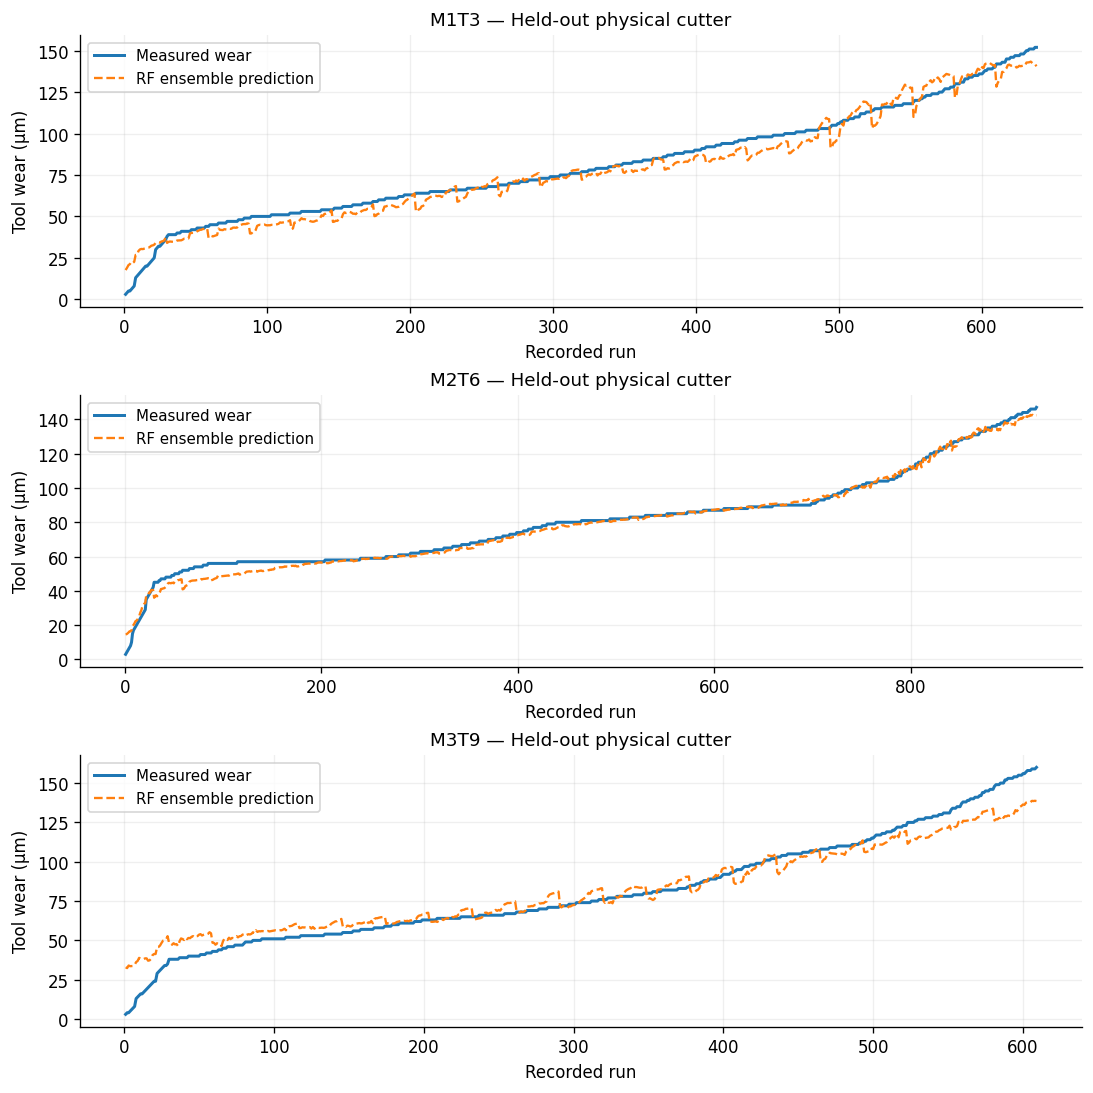

Saved: F1_wear_trajectories


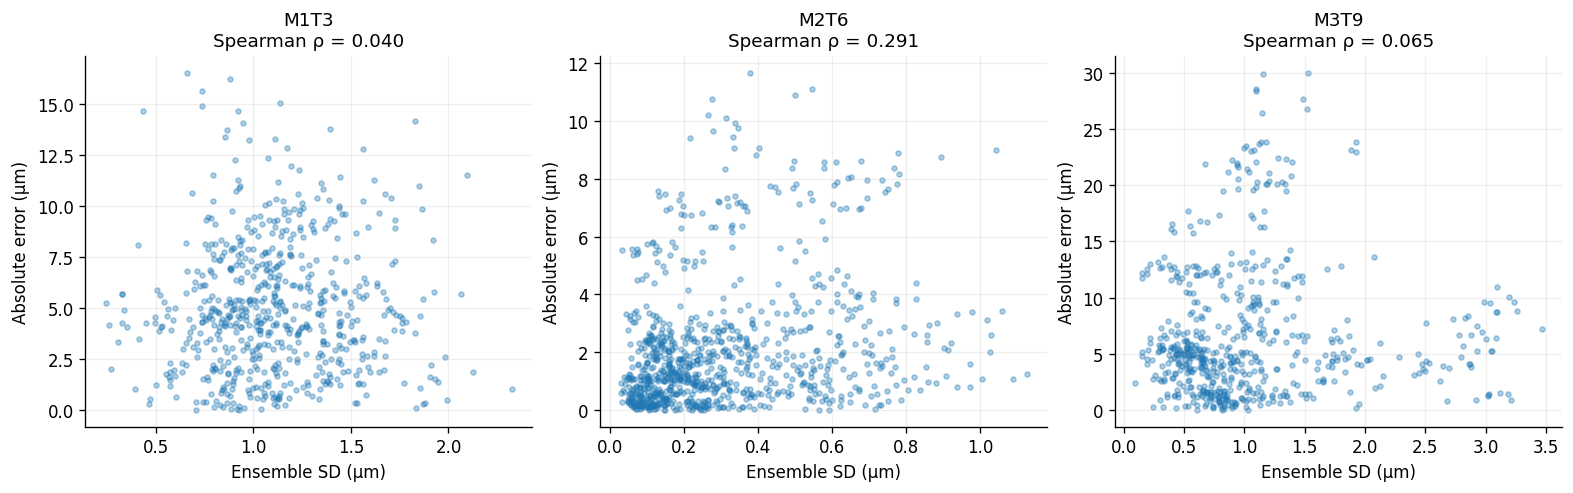

Saved: F2_disagreement_vs_error


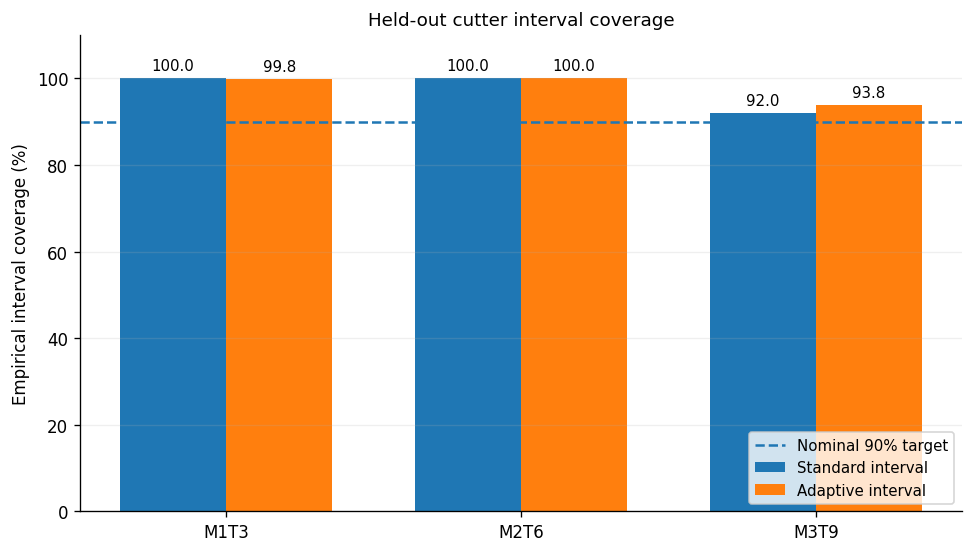

Saved: F3_interval_coverage


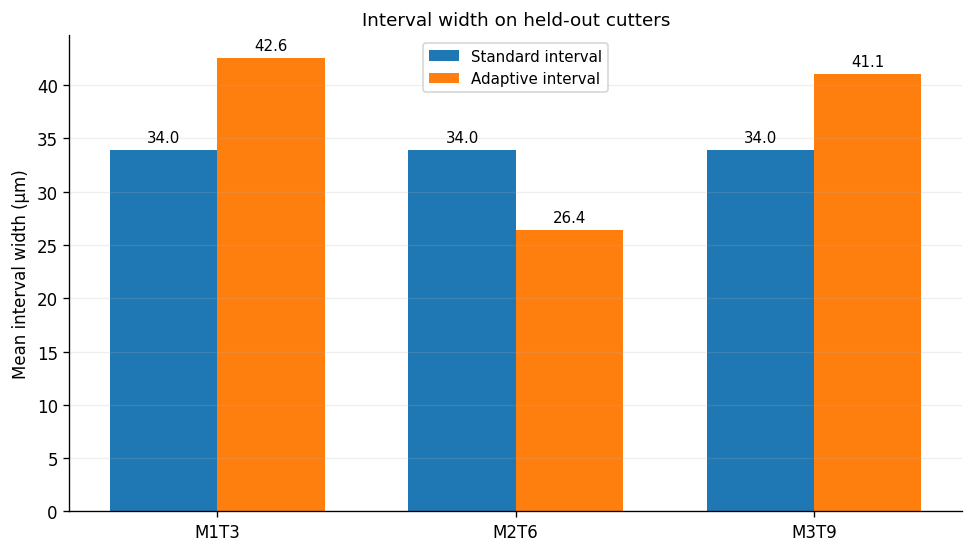

Saved: F4_interval_width


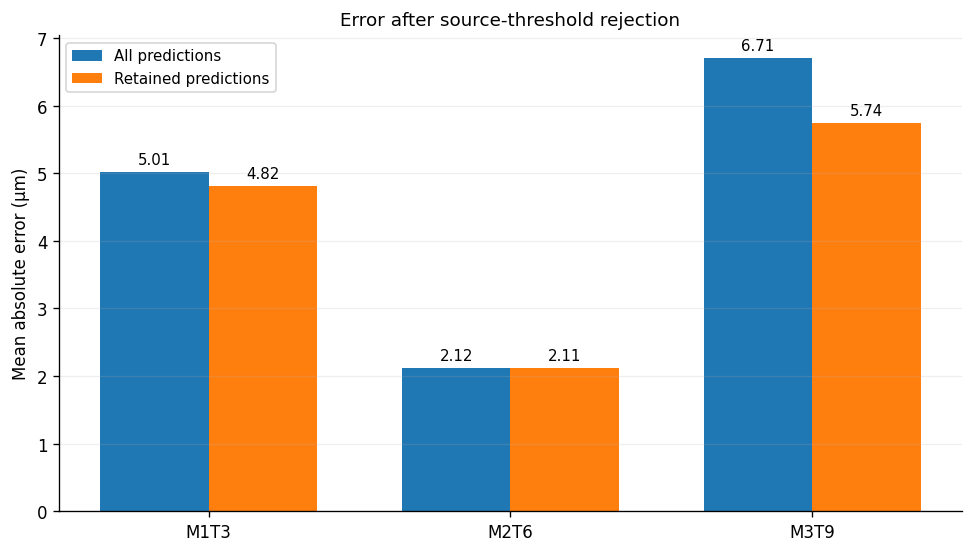

Saved: F5_selective_prediction_mae


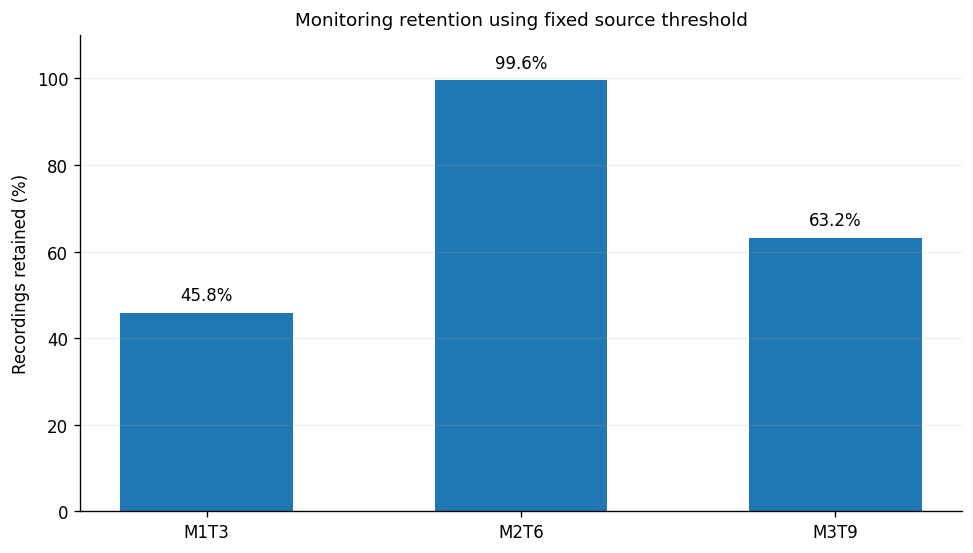

Saved: F6_monitoring_retention

PUBLICATION OUTPUTS COMPLETE
Figures: /kaggle/working/nine_tool_validation/publication_figures
Tables: /kaggle/working/nine_tool_validation/publication_tables
ZIP file: /kaggle/working/nine_tool_validation/nine_tool_publication_outputs.zip

Generated 6 figures in PNG + PDF format.
Generated 4 CSV tables.
No model retraining or test-based tuning performed.


In [11]:

from pathlib import Path
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================================
# STEP 9 — PUBLICATION FIGURES AND TABLES
# Uses saved held-out results only. No training or tuning.
# ==========================================================

ROOT = Path("/kaggle/working/nine_tool_validation")
FIG_DIR = ROOT / "publication_figures"
TABLE_DIR = ROOT / "publication_tables"

FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

pred = pd.read_csv(ROOT / "final_test_predictions.csv")
metrics = pd.read_csv(ROOT / "final_test_per_tool_metrics.csv")

with open(ROOT / "locked_test_specification.json") as f:
    spec = json.load(f)

TOOLS = ["M1T3", "M2T6", "M3T9"]
NOMINAL = 100 * spec["nominal_coverage"]

# Confirm that we are using the frozen final-test results.
assert len(pred) == 2175
assert set(pred["physical_tool"]) == set(TOOLS)
assert set(metrics["tool"]) == set(TOOLS)
assert pred["filename"].is_unique

assert all(
    pred["physical_tool"].value_counts()[t] == n
    for t, n in [("M1T3", 638), ("M2T6", 928), ("M3T9", 609)]
)

required = [
    "wear", "run", "physical_tool",
    "single_rf_prediction_um",
    "ensemble_prediction_um",
    "ensemble_sd_um",
    "absolute_error_um",
    "standard_lower_um",
    "standard_upper_um",
    "adaptive_lower_um",
    "adaptive_upper_um",
    "retained_by_uncertainty"
]

assert set(required).issubset(pred.columns)

print("Final held-out data verified.")
print("Recordings:", len(pred))

# ==========================================================
# PLOT SETTINGS
# ==========================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_figure(fig, name):
    fig.savefig(
        FIG_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )
    fig.savefig(
        FIG_DIR / f"{name}.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)
    print("Saved:", name)

def tool_data(tool):
    return (
        pred.loc[pred["physical_tool"] == tool]
        .sort_values("run")
        .reset_index(drop=True)
    )

# ==========================================================
# FIGURE 1 — ACTUAL VS PREDICTED WEAR TRAJECTORIES
# ==========================================================

fig, axes = plt.subplots(
    3, 1, figsize=(9, 9), constrained_layout=True
)

for ax, tool in zip(axes, TOOLS):
    d = tool_data(tool)

    x = d["run"].to_numpy()
    actual = d["wear"].to_numpy()
    predicted = d["ensemble_prediction_um"].to_numpy()

    ax.plot(
        x, actual,
        linewidth=1.8,
        label="Measured wear"
    )

    ax.plot(
        x, predicted,
        linewidth=1.4,
        linestyle="--",
        label="RF ensemble prediction"
    )

    ax.set_title(
        f"{tool} — Held-out physical cutter"
    )
    ax.set_xlabel("Recorded run")
    ax.set_ylabel("Tool wear (µm)")
    ax.grid(alpha=0.2)

    ax.legend(loc="best")

save_figure(fig, "F1_wear_trajectories")

# ==========================================================
# FIGURE 2 — ENSEMBLE DISAGREEMENT VS ABSOLUTE ERROR
# ==========================================================

fig, axes = plt.subplots(
    1, 3, figsize=(13, 4), constrained_layout=True
)

for ax, tool in zip(axes, TOOLS):
    d = tool_data(tool)

    ax.scatter(
        d["ensemble_sd_um"],
        d["absolute_error_um"],
        s=9,
        alpha=0.35,
        rasterized=True
    )

    rho = float(
        metrics.loc[
            metrics["tool"] == tool,
            "spearman_sd_abs_error"
        ].iloc[0]
    )

    ax.set_title(
        f"{tool}\nSpearman ρ = {rho:.3f}"
    )
    ax.set_xlabel("Ensemble SD (µm)")
    ax.set_ylabel("Absolute error (µm)")
    ax.grid(alpha=0.2)

save_figure(fig, "F2_disagreement_vs_error")

# ==========================================================
# FIGURE 3 — INTERVAL COVERAGE
# ==========================================================

m = metrics.set_index("tool").loc[TOOLS]

x = np.arange(len(TOOLS))
width = 0.36

standard_coverage = (
    m["standard_coverage"].to_numpy() * 100
)
adaptive_coverage = (
    m["adaptive_coverage"].to_numpy() * 100
)

fig, ax = plt.subplots(
    figsize=(8, 4.5), constrained_layout=True
)

bars1 = ax.bar(
    x - width / 2,
    standard_coverage,
    width,
    label="Standard interval"
)

bars2 = ax.bar(
    x + width / 2,
    adaptive_coverage,
    width,
    label="Adaptive interval"
)

ax.axhline(
    NOMINAL,
    linestyle="--",
    linewidth=1.5,
    label="Nominal 90% target"
)

ax.set_xticks(x)
ax.set_xticklabels(TOOLS)
ax.set_ylabel("Empirical interval coverage (%)")
ax.set_ylim(0, 110)
ax.set_title("Held-out cutter interval coverage")
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="lower right")

for bars in (bars1, bars2):
    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

save_figure(fig, "F3_interval_coverage")

# ==========================================================
# FIGURE 4 — INTERVAL WIDTHS
# ==========================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5), constrained_layout=True
)

bars1 = ax.bar(
    x - width / 2,
    m["standard_width_um"],
    width,
    label="Standard interval"
)

bars2 = ax.bar(
    x + width / 2,
    m["adaptive_width_um"],
    width,
    label="Adaptive interval"
)

ax.set_xticks(x)
ax.set_xticklabels(TOOLS)
ax.set_ylabel("Mean interval width (µm)")
ax.set_title("Interval width on held-out cutters")
ax.grid(axis="y", alpha=0.2)
ax.legend()

for bars in (bars1, bars2):
    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

save_figure(fig, "F4_interval_width")

# ==========================================================
# FIGURE 5 — FULL VS RETAINED MAE
# ==========================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5), constrained_layout=True
)

bars1 = ax.bar(
    x - width / 2,
    m["ensemble_mae_um"],
    width,
    label="All predictions"
)

bars2 = ax.bar(
    x + width / 2,
    m["retained_mae_um"],
    width,
    label="Retained predictions"
)

ax.set_xticks(x)
ax.set_xticklabels(TOOLS)
ax.set_ylabel("Mean absolute error (µm)")
ax.set_title("Error after source-threshold rejection")
ax.grid(axis="y", alpha=0.2)
ax.legend()

for bars in (bars1, bars2):
    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

save_figure(fig, "F5_selective_prediction_mae")

# ==========================================================
# FIGURE 6 — FRACTION OF RECORDINGS RETAINED
# ==========================================================

fig, ax = plt.subplots(
    figsize=(8, 4.5), constrained_layout=True
)

retention = m["retained_fraction"].to_numpy() * 100

bars = ax.bar(
    x,
    retention,
    width=0.55
)

ax.set_xticks(x)
ax.set_xticklabels(TOOLS)
ax.set_ylabel("Recordings retained (%)")
ax.set_ylim(0, 110)
ax.set_title("Monitoring retention using fixed source threshold")
ax.grid(axis="y", alpha=0.2)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{bar.get_height():.1f}%",
        ha="center",
        va="bottom"
    )

save_figure(fig, "F6_monitoring_retention")

# ==========================================================
# PUBLICATION TABLES
# ==========================================================

# Table 1: Point-prediction accuracy
table1 = m[[
    "n",
    "single_rf_mae_um",
    "ensemble_mae_um",
    "ensemble_rmse_um",
    "ensemble_r2",
    "signed_error_um"
]].copy()

table1.loc["Macro"] = table1.mean(numeric_only=True)
table1.loc["Macro", "n"] = len(pred)
table1.to_csv(
    TABLE_DIR / "T1_prediction_accuracy.csv"
)

# Table 2: Interval coverage and width
table2 = m[[
    "standard_coverage",
    "adaptive_coverage",
    "standard_width_um",
    "adaptive_width_um",
    "standard_below_lower",
    "standard_above_upper",
    "adaptive_below_lower",
    "adaptive_above_upper"
]].copy()

table2.loc["Macro"] = table2.mean(numeric_only=True)
table2.to_csv(
    TABLE_DIR / "T2_interval_reliability.csv"
)

# Table 3: Selective prediction
table3 = m[[
    "spearman_sd_abs_error",
    "retained_fraction",
    "ensemble_mae_um",
    "retained_mae_um"
]].copy()

table3.loc["Macro"] = table3.mean(numeric_only=True)
table3.to_csv(
    TABLE_DIR / "T3_selective_prediction.csv"
)

# Table 4: Data and experimental split
table4 = pd.DataFrame({
    "physical_tool": [
        "M1T1", "M1T2", "M1T3",
        "M2T4", "M2T5", "M2T6",
        "M3T7", "M3T8", "M3T9"
    ],
    "machine": [1, 1, 1, 2, 2, 2, 3, 3, 3],
    "split": [
        "Source", "Source", "Held-out",
        "Source", "Source", "Held-out",
        "Source", "Source", "Held-out"
    ],
    "recordings": [
        609, 609, 638,
        928, 928, 928,
        609, 560, 609
    ]
})

table4.to_csv(
    TABLE_DIR / "T4_dataset_split.csv",
    index=False
)

# ==========================================================
# SAVE ANALYSIS MANIFEST
# ==========================================================

manifest = {
    "experiment": "nine_tool_publication_outputs_v1",
    "input_predictions": "final_test_predictions.csv",
    "input_metrics": "final_test_per_tool_metrics.csv",
    "source_threshold_um": float(
        spec["source_sd_threshold_um"]
    ),
    "test_tools": TOOLS,
    "model_refitted": False,
    "thresholds_modified": False,
    "output_figures": 6,
    "output_tables": 4,
    "notes": [
        "All figures use previously frozen held-out predictions.",
        "Tool-level macro averages weight each cutter equally.",
        "Retained MAE conditions on a selected subset.",
        "Conformal coverage is empirical, not guaranteed.",
        "Sequential recordings within tools are dependent."
    ]
}

with open(FIG_DIR / "publication_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

# ==========================================================
# ZIP FIGURES AND TABLES
# ==========================================================

zip_path = ROOT / "nine_tool_publication_outputs.zip"

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:

    for directory in [FIG_DIR, TABLE_DIR]:
        for file in sorted(directory.iterdir()):
            if file.is_file():
                archive.write(
                    file,
                    arcname=f"{directory.name}/{file.name}"
                )

print("\n" + "=" * 50)
print("PUBLICATION OUTPUTS COMPLETE")
print("=" * 50)

print("Figures:", FIG_DIR)
print("Tables:", TABLE_DIR)
print("ZIP file:", zip_path)

print("\nGenerated 6 figures in PNG + PDF format.")
print("Generated 4 CSV tables.")
print("No model retraining or test-based tuning performed.")


In [12]:
from IPython.display import FileLink, display

display(
    FileLink(
        "/kaggle/working/nine_tool_validation/"
        "nine_tool_publication_outputs.zip"
    )
)

/kaggle/working/nine_tool_validation/nine_tool_publication_outputs.zip